In [2]:
import sys
import numpy
import pandas
import sklearn
import scipy

print("Python:", sys.version)
print("numpy:", numpy.__version__)
print("pandas:", pandas.__version__)
print("scikit-learn:", sklearn.__version__)
print("scipy:", scipy.__version__)

try:
    import torch
    print("torch:", torch.__version__)
except ImportError:
    print("torch: not installed")

Python: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
numpy: 1.26.4
pandas: 2.2.3
scikit-learn: 1.5.2
scipy: 1.17.1
torch: 2.7.1+cpu


In [3]:
from pathlib import Path
import os
import random
import warnings
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import mlflow
import mlflow.pyfunc
from mlflow.tracking import MlflowClient

from dotenv import load_dotenv
from os import getenv

warnings.filterwarnings("ignore")

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# Same thresholds as your latest A14_test notebook
ACCEPT_THRESHOLD = 0.53
WARN_THRESHOLD = 0.50

POSE_WEIGHT = 0.50
KEYPOINT_WEIGHT = 0.50

SEQ_LEN = 10

# Change this if your env file is somewhere else
load_dotenv("../../../../../env")

tracking_uri = getenv("MLFLOW_TRACKING_URI")
print("MLFLOW_TRACKING_URI =", tracking_uri)

if tracking_uri:
    mlflow.set_tracking_uri(tracking_uri)
else:
    raise RuntimeError("MLFLOW_TRACKING_URI not set. Fix the env path or variable.")

EXPERIMENT_NAME = "A14_combined_pose_keypoint_confidence_test"
mlflow.set_experiment(EXPERIMENT_NAME)

client = MlflowClient()

print("MLflow tracking URI:", mlflow.get_tracking_uri())
print("MLflow experiment:", EXPERIMENT_NAME)

c:\Users\kimwo\software engineering\year 4\LP3\4DT907 - Project\machine_learning_project_4dt907\.venv_a14\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


MLFLOW_TRACKING_URI = https://172.27.62.170:5001/
MLflow tracking URI: https://172.27.62.170:5001/
MLflow experiment: A14_combined_pose_keypoint_confidence_test


In [4]:
# Option 1:
# If you already know the exact model URI, paste it here, for example:
# MODEL_URI = "runs:/abc123/model"

MODEL_URI = "runs:/8941f8189ec0488aa90dcd1223b18dc5/model"

if MODEL_URI is None:
    experiment = client.get_experiment_by_name(EXPERIMENT_NAME)

    if experiment is None:
        raise RuntimeError(f"Could not find MLflow experiment: {EXPERIMENT_NAME}")

    runs = client.search_runs(
        experiment_ids=[experiment.experiment_id],
        filter_string="params.task = 'combined_pose_keypoint_ugly_recording_regression'",
        order_by=["attributes.start_time DESC"],
        max_results=20,
    )

    if len(runs) == 0:
        raise RuntimeError(
            "No logged A14 combined confidence model run was found. "
            "Run the final MLflow logging cell in A14_test.ipynb first."
        )

    candidate_rows = []

    for run in runs:
        run_name = run.data.tags.get("mlflow.runName", "")
        candidate_rows.append({
            "run_id": run.info.run_id,
            "run_name": run_name,
            "status": run.info.status,
            "start_time": run.info.start_time,
            "model_family": run.data.params.get("model_family"),
            "feature_set": run.data.params.get("feature_set"),
            "seq_len": run.data.params.get("seq_len"),
            "accept_threshold": run.data.params.get("accept_threshold"),
            "warn_threshold": run.data.params.get("warn_threshold"),
        })

    candidate_df = pd.DataFrame(candidate_rows)
    display(candidate_df)

    best_run = runs[0]
    MODEL_URI = f"runs:/{best_run.info.run_id}/model"

print("Using MODEL_URI:")
print(MODEL_URI)

Using MODEL_URI:
runs:/8941f8189ec0488aa90dcd1223b18dc5/model


In [72]:
# Put IMG_1880_movenet_cut.csv in the same folder as this notebook.
# If needed, change this path manually.

#WIN_20260520_09_08_02_Pro_movenet_cut.csv
CSV_CANDIDATES = [
    #Path("IMG_1883_movenet_cut.csv"),
    #Path("WIN_20260520_09_08_02_Pro_movenet_cut.csv"),
    #Path("WIN_20260520_09_33_16_Pro_movenet_cut.csv"),
    Path("WIN_20260520_09_53_38_Pro_movenet_cut.csv"),
    #Path("IMG_1884_movenet_cut.csv"),
    #Path("../IMG_1880_movenet_cut.csv"),
    #Path("../../IMG_1880_movenet_cut.csv"),
    #Path("/mnt/data/IMG_1880_movenet_cut.csv"),  # works in ChatGPT sandbox only
]

CAMERA_TEST_CSV = None

for candidate in CSV_CANDIDATES:
    if candidate.exists():
        CAMERA_TEST_CSV = candidate
        break

if CAMERA_TEST_CSV is None:
    raise FileNotFoundError(
        "Could not find IMG_1880_movenet_cut.csv. "
        "Place it next to this notebook or update CSV_CANDIDATES."
    )

raw_df = pd.read_csv(CAMERA_TEST_CSV)
raw_df.columns = [str(c).strip() for c in raw_df.columns]

raw_df["sequence_id"] = CAMERA_TEST_CSV.stem

print("Loaded:", CAMERA_TEST_CSV)
print("Shape:", raw_df.shape)
display(raw_df.head())
print("Columns:")
print(raw_df.columns.tolist())

Loaded: WIN_20260520_09_53_38_Pro_movenet_cut.csv
Shape: (57, 54)


,timestamp_ms,frame_index,nose_x,nose_y,nose_score,left_eye_x,left_eye_y,left_eye_score,right_eye_x,right_eye_y,...,right_knee_x,right_knee_y,right_knee_score,left_ankle_x,left_ankle_y,left_ankle_score,right_ankle_x,right_ankle_y,right_ankle_score,sequence_id
0,500,5,547.89,94.57,0.4994,563.01,82.12,0.5812,535.51,83.03,...,506.99,561.83,0.7716,624.69,695.48,0.7181,502.45,690.55,0.5560,WIN_20260520_09_53_38_Pro_movenet_cut
1,600,6,547.85,89.19,0.7281,562.36,77.94,0.7920,534.36,77.97,...,499.21,550.77,0.7969,599.80,695.54,0.6630,493.67,689.38,0.5763,WIN_20260520_09_53_38_Pro_movenet_cut
2,700,7,523.16,85.61,0.6600,538.10,74.87,0.8451,509.18,75.04,...,488.22,546.04,0.8294,601.14,685.90,0.5502,487.09,685.29,0.4916,WIN_20260520_09_53_38_Pro_movenet_cut
3,800,8,551.26,68.72,0.7746,564.90,57.11,0.4624,535.93,57.77,...,498.82,537.67,0.8829,616.73,673.51,0.5747,485.34,679.08,0.7451,WIN_20260520_09_53_38_Pro_movenet_cut
4,900,9,485.45,71.51,0.4762,499.94,59.84,0.5754,471.37,60.97,...,433.69,557.88,0.7817,555.66,694.99,0.7796,426.84,692.77,0.7908,WIN_20260520_09_53_38_Pro_movenet_cut


Columns:
['timestamp_ms', 'frame_index', 'nose_x', 'nose_y', 'nose_score', 'left_eye_x', 'left_eye_y', 'left_eye_score', 'right_eye_x', 'right_eye_y', 'right_eye_score', 'left_ear_x', 'left_ear_y', 'left_ear_score', 'right_ear_x', 'right_ear_y', 'right_ear_score', 'left_shoulder_x', 'left_shoulder_y', 'left_shoulder_score', 'right_shoulder_x', 'right_shoulder_y', 'right_shoulder_score', 'left_elbow_x', 'left_elbow_y', 'left_elbow_score', 'right_elbow_x', 'right_elbow_y', 'right_elbow_score', 'left_wrist_x', 'left_wrist_y', 'left_wrist_score', 'right_wrist_x', 'right_wrist_y', 'right_wrist_score', 'left_hip_x', 'left_hip_y', 'left_hip_score', 'right_hip_x', 'right_hip_y', 'right_hip_score', 'left_knee_x', 'left_knee_y', 'left_knee_score', 'right_knee_x', 'right_knee_y', 'right_knee_score', 'left_ankle_x', 'left_ankle_y', 'left_ankle_score', 'right_ankle_x', 'right_ankle_y', 'right_ankle_score', 'sequence_id']


In [73]:
FRAME_COL_CANDIDATES = [
    "frame_index",
    "frame",
    "frame_id",
    "Frame",
    "FrameID",
    "FrameNo",
    "frame_no",
    "image_id",
    "image_index",
]

POSE_SCORE_CANDIDATES = [
    "pose_score",
    "pose_confidence",
    "movenet_score",
    "movenet_pose_score",
    "score",
    "confidence",
]

MOVENET_TO_ASSIGNMENT = {
    "nose": "head",
    "left_shoulder": "left_shoulder",
    "left_elbow": "left_elbow",
    "right_shoulder": "right_shoulder",
    "right_elbow": "right_elbow",
    "left_wrist": "left_hand",
    "right_wrist": "right_hand",
    "left_hip": "left_hip",
    "right_hip": "right_hip",
    "left_knee": "left_knee",
    "right_knee": "right_knee",
    "left_ankle": "left_foot",
    "right_ankle": "right_foot",
}

JOINTS_13 = list(MOVENET_TO_ASSIGNMENT.values())
SCORE_COLS = [f"{joint}_score" for joint in JOINTS_13]


def find_frame_col(df: pd.DataFrame) -> str:
    for col in FRAME_COL_CANDIDATES:
        if col in df.columns:
            return col

    raise ValueError(f"No frame column found. Available columns: {df.columns.tolist()}")


def find_pose_score_col(df: pd.DataFrame) -> str | None:
    for col in POSE_SCORE_CANDIDATES:
        if col in df.columns:
            return col

    return None


def load_movenet_as_assignment_df(df: pd.DataFrame) -> pd.DataFrame:
    """
    Converts raw MoveNet columns to the 13-joint assignment format used by A14.
    If there is no explicit pose score column, pose_score is approximated as
    the mean keypoint score per frame.
    """
    df = df.copy()
    df.columns = [str(c).strip() for c in df.columns]

    frame_col = find_frame_col(df)
    pose_col = find_pose_score_col(df)

    out = pd.DataFrame()
    out["frame_index"] = pd.to_numeric(df[frame_col], errors="coerce").astype(int)

    for movenet_joint, assignment_joint in MOVENET_TO_ASSIGNMENT.items():
        for suffix in ["x", "y", "score"]:
            src = f"{movenet_joint}_{suffix}"
            dst = f"{assignment_joint}_{suffix}"

            if src in df.columns:
                out[dst] = pd.to_numeric(df[src], errors="coerce")
            elif dst in df.columns:
                out[dst] = pd.to_numeric(df[dst], errors="coerce")
            else:
                raise ValueError(f"Missing required column: {src} or {dst}")

    if pose_col is not None:
        out["pose_score"] = pd.to_numeric(df[pose_col], errors="coerce")
        out["pose_score_source"] = pose_col
    else:
        out["pose_score"] = out[SCORE_COLS].mean(axis=1)
        out["pose_score_source"] = "mean_keypoint_fallback"

    out = out.sort_values("frame_index").reset_index(drop=True)
    return out


def calculate_confidence_summary(df: pd.DataFrame, label: str) -> dict:
    keypoint_scores = df[SCORE_COLS].to_numpy(dtype=np.float32)
    pose_scores = df["pose_score"].to_numpy(dtype=np.float32)

    pose_confidence = float(np.nanmean(pose_scores))
    keypoint_confidence = float(np.nanmean(keypoint_scores))
    combined_confidence = (
        POSE_WEIGHT * pose_confidence
        + KEYPOINT_WEIGHT * keypoint_confidence
    )

    below_030 = keypoint_scores < 0.30
    frame_has_low_keypoint = np.any(below_030, axis=1)

    return {
        "scope": label,
        "n_frames": len(df),
        "pose_score_source": df["pose_score_source"].iloc[0],
        "raw_pose_confidence": pose_confidence,
        "raw_keypoint_confidence": keypoint_confidence,
        "raw_combined_confidence": combined_confidence,
        "min_keypoint_confidence": float(np.nanmin(keypoint_scores)),
        "p10_keypoint_confidence": float(np.nanpercentile(keypoint_scores, 10)),
        "fraction_keypoints_below_030": float(np.nanmean(below_030)),
        "fraction_frames_with_any_keypoint_below_030": float(np.mean(frame_has_low_keypoint)),
    }


def decision_from_score(score: float) -> str:
    if score >= ACCEPT_THRESHOLD:
        return "accept"
    if score >= WARN_THRESHOLD:
        return "warn"
    return "reject"

In [74]:
assignment_df = load_movenet_as_assignment_df(raw_df)

confidence_rows = []

# Important: the trained A14 model uses only the first c = 10 frames.
confidence_rows.append(
    calculate_confidence_summary(
        assignment_df.head(SEQ_LEN),
        label=f"first_{SEQ_LEN}_frames_used_by_model",
    )
)

# This is useful for analyzing the full 4K recording, even though the model does not use all frames.
confidence_rows.append(
    calculate_confidence_summary(
        assignment_df,
        label="all_frames_in_recording",
    )
)

confidence_summary_df = pd.DataFrame(confidence_rows)
confidence_summary_df["raw_decision"] = confidence_summary_df["raw_combined_confidence"].apply(decision_from_score)

display(confidence_summary_df)

print("Interpretation:")
print(
    "The row 'first_10_frames_used_by_model' is the most comparable to the trained A14 model, "
    "because the model was trained to use only the first c = 10 frames."
)
print(
    "The row 'all_frames_in_recording' is useful for checking whether the whole 4K recording "
    "has stable keypoint confidence."
)

,scope,n_frames,pose_score_source,raw_pose_confidence,raw_keypoint_confidence,raw_combined_confidence,min_keypoint_confidence,p10_keypoint_confidence,fraction_keypoints_below_030,fraction_frames_with_any_keypoint_below_030,raw_decision
0,first_10_frames_used_by_model,10,mean_keypoint_fallback,0.68487,0.68487,0.68487,0.3199,0.47458,0.000000,0.000000,accept
1,all_frames_in_recording,57,mean_keypoint_fallback,0.63883,0.63883,0.63883,0.0286,0.38290,0.068826,0.508772,accept


Interpretation:
The row 'first_10_frames_used_by_model' is the most comparable to the trained A14 model, because the model was trained to use only the first c = 10 frames.
The row 'all_frames_in_recording' is useful for checking whether the whole 4K recording has stable keypoint confidence.


In [8]:
loaded_model = mlflow.pyfunc.load_model(MODEL_URI)



2026/05/20 09:22:48 WARNING mlflow.utils.requirements_utils: Detected one or more mismatches between the model's dependencies and the current Python environment:
 - mlflow (current: 3.12.0, required: mlflow==3.9.0)
To fix the mismatches, call `mlflow.pyfunc.get_model_dependencies(model_uri)` to fetch the model's environment and install dependencies using the resulting environment file.


In [75]:
model_prediction_df = loaded_model.predict(raw_df)

display(model_prediction_df)

predicted_combined = float(model_prediction_df["weighted_combined_confidence"].iloc[0])
predicted_decision = model_prediction_df["decision"].iloc[0]

print("Predicted weighted combined confidence:", predicted_combined)
print("Predicted decision:", predicted_decision)

,sequence_id,predicted_pose_confidence,predicted_keypoint_confidence,predicted_combined_confidence,weighted_combined_confidence,decision,accept_threshold,warn_threshold
0,WIN_20260520_09_53_38_Pro_movenet_cut,0.541285,0.533399,0.553021,0.537342,accept,0.53,0.5


Predicted weighted combined confidence: 0.5373419523239136
Predicted decision: accept


In [76]:
first_10_raw = confidence_summary_df[
    confidence_summary_df["scope"] == f"first_{SEQ_LEN}_frames_used_by_model"
].iloc[0]

all_frames_raw = confidence_summary_df[
    confidence_summary_df["scope"] == "all_frames_in_recording"
].iloc[0]

comparison_df = pd.DataFrame([
    {
        "source": "Raw calculation, first 10 frames",
        "pose_confidence": first_10_raw["raw_pose_confidence"],
        "keypoint_confidence": first_10_raw["raw_keypoint_confidence"],
        "combined_confidence": first_10_raw["raw_combined_confidence"],
        "decision": first_10_raw["raw_decision"],
    },
    {
        "source": "Raw calculation, all frames",
        "pose_confidence": all_frames_raw["raw_pose_confidence"],
        "keypoint_confidence": all_frames_raw["raw_keypoint_confidence"],
        "combined_confidence": all_frames_raw["raw_combined_confidence"],
        "decision": all_frames_raw["raw_decision"],
    },
    {
        "source": "MLflow model prediction",
        "pose_confidence": float(model_prediction_df["predicted_pose_confidence"].iloc[0]),
        "keypoint_confidence": float(model_prediction_df["predicted_keypoint_confidence"].iloc[0]),
        "combined_confidence": float(model_prediction_df["weighted_combined_confidence"].iloc[0]),
        "decision": model_prediction_df["decision"].iloc[0],
    },
])

display(comparison_df)

print("Camera quality test result:")
print(
    f"The MLflow model predicts combined confidence = "
    f"{comparison_df.loc[comparison_df['source'] == 'MLflow model prediction', 'combined_confidence'].iloc[0]:.4f} "
    f"with decision '{comparison_df.loc[comparison_df['source'] == 'MLflow model prediction', 'decision'].iloc[0]}'."
)

,source,pose_confidence,keypoint_confidence,combined_confidence,decision
0,"Raw calculation, first 10 frames",0.684870,0.684870,0.684870,accept
1,"Raw calculation, all frames",0.638830,0.638830,0.638830,accept
2,MLflow model prediction,0.541285,0.533399,0.537342,accept


Camera quality test result:
The MLflow model predicts combined confidence = 0.5373 with decision 'accept'.


In [68]:
joint_summary_rows = []

for joint in JOINTS_13:
    score_col = f"{joint}_score"

    joint_summary_rows.append({
        "joint": joint,
        "mean_score_all_frames": assignment_df[score_col].mean(),
        "mean_score_first_10_frames": assignment_df.head(SEQ_LEN)[score_col].mean(),
        "min_score_all_frames": assignment_df[score_col].min(),
        "p10_score_all_frames": assignment_df[score_col].quantile(0.10),
        "fraction_below_030_all_frames": (assignment_df[score_col] < 0.30).mean(),
    })

joint_summary_df = pd.DataFrame(joint_summary_rows)
joint_summary_df = joint_summary_df.sort_values("mean_score_all_frames").reset_index(drop=True)

display(joint_summary_df)

print("Lowest-confidence joints:")
display(joint_summary_df.head(5))

,joint,mean_score_all_frames,mean_score_first_10_frames,min_score_all_frames,p10_score_all_frames,fraction_below_030_all_frames
0,left_foot,0.307189,0.15619,0.0809,0.12782,0.700000
1,right_foot,0.340134,0.32995,0.0756,0.17563,0.528571
2,right_elbow,0.438439,0.64439,0.2085,0.29196,0.157143
3,right_hand,0.466176,0.69569,0.1391,0.33566,0.085714
4,right_shoulder,0.546417,0.80780,0.2682,0.33397,0.014286
5,right_knee,0.553877,0.43782,0.1705,0.29505,0.114286
6,head,0.585489,0.73556,0.3980,0.43713,0.000000
7,right_hip,0.647227,0.75443,0.4019,0.50107,0.000000
8,left_elbow,0.701831,0.73392,0.4849,0.59905,0.000000
9,left_knee,0.759471,0.54965,0.1169,0.60144,0.014286


Lowest-confidence joints:


,joint,mean_score_all_frames,mean_score_first_10_frames,min_score_all_frames,p10_score_all_frames,fraction_below_030_all_frames
0,left_foot,0.307189,0.15619,0.0809,0.12782,0.700000
1,right_foot,0.340134,0.32995,0.0756,0.17563,0.528571
2,right_elbow,0.438439,0.64439,0.2085,0.29196,0.157143
3,right_hand,0.466176,0.69569,0.1391,0.33566,0.085714
4,right_shoulder,0.546417,0.80780,0.2682,0.33397,0.014286


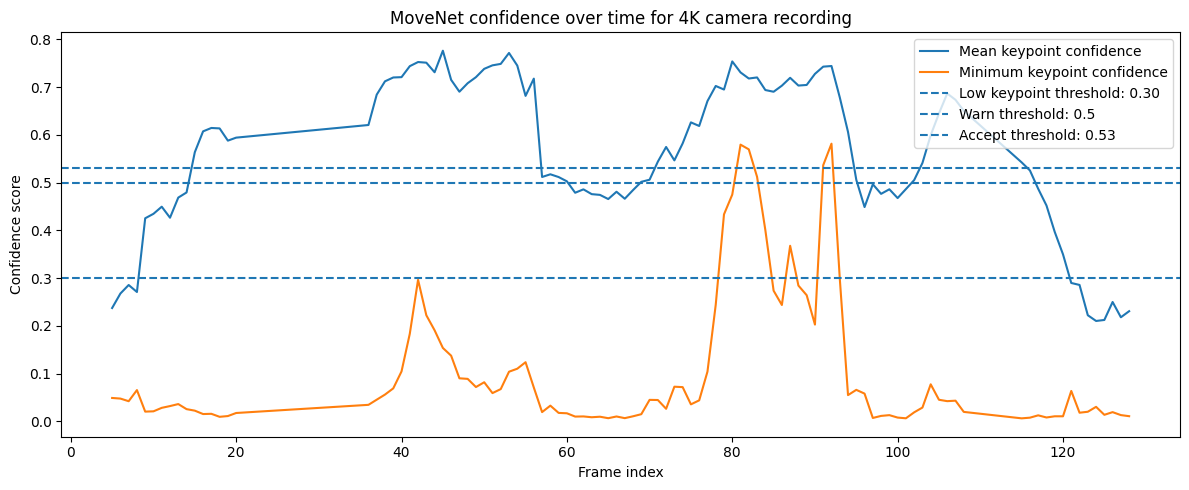

In [18]:
plot_df = assignment_df.copy()
plot_df["mean_keypoint_score"] = plot_df[SCORE_COLS].mean(axis=1)
plot_df["min_keypoint_score"] = plot_df[SCORE_COLS].min(axis=1)

plt.figure(figsize=(12, 5))
plt.plot(plot_df["frame_index"], plot_df["mean_keypoint_score"], label="Mean keypoint confidence")
plt.plot(plot_df["frame_index"], plot_df["min_keypoint_score"], label="Minimum keypoint confidence")
plt.axhline(0.30, linestyle="--", label="Low keypoint threshold: 0.30")
plt.axhline(WARN_THRESHOLD, linestyle="--", label=f"Warn threshold: {WARN_THRESHOLD}")
plt.axhline(ACCEPT_THRESHOLD, linestyle="--", label=f"Accept threshold: {ACCEPT_THRESHOLD}")
plt.title("MoveNet confidence over time for 4K camera recording")
plt.xlabel("Frame index")
plt.ylabel("Confidence score")
plt.legend()
plt.tight_layout()
plt.show()